# 01 — Data Pipeline, Exploratory Analysis & Aligned Strip Packing

**Companion links:** [README.md](../README.md) (Section 1 overview) | [docs/01_data_pipeline_and_eda.md](../docs/01_data_pipeline_and_eda.md) (derivations and parameters).

**Goal:** Empirically verify every data handling, normalization, seasonal lag, and batch-packing decision built into `gifteval-tsfm-prototype` against real shards from [`theforecastingcompany/GiftEvalPretrain`](https://huggingface.co/datasets/theforecastingcompany/GiftEvalPretrain).

Each section poses a concrete engineering question, walks through the math and implementation in `src/tsfm_proto/`, and visualizes the exact empirical evidence.

In [1]:
from __future__ import annotations

import json
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq

REPO_ROOT = Path.cwd() if (Path.cwd() / "src" / "tsfm_proto").exists() else Path.cwd().parent
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

from tsfm_proto.config import TSFMConfig
from tsfm_proto.data import SubsetDatasetStore, make_step_rng, normalize_pandas_freq
from tsfm_proto.packing import pack_strip_batch
from tsfm_proto.scaling import _scale_equivariant_stats_1d, build_group_patch_features

plt.rcParams.update(
    {
        "figure.dpi": 115,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
    }
)
print(f"Repository: {REPO_ROOT.name} (src/tsfm_proto present={(REPO_ROOT / 'src' / 'tsfm_proto').exists()})")

Repository: gifteval-tsfm-prototype (src/tsfm_proto present=True)


## 1. Full Corpus Pareto Skew & Stratified Subset Construction

**Question:** Why sample a `2.74 GB` compressed multi-shard subset across `93` directories instead of streaming `100%` of the `878.26 GB` full corpus?

Loading `results/eda_dataset_catalog.csv` (`152` Parquet directories, `3,490,516` series) shows extreme storage and count skew:
- Gridded climate outputs (`63` `cmip6_*` and `era5_*` directories) account for `90.2%` of total compressed bytes.
- Simulated building energy traces (`buildings_900k`) alone account for `51.4%` of all series in the full corpus.
- Conversely, all `67` small/medium datasets (`<= 2,000` series each) require just `2.60 GB` in total—`0.3%` of the corpus bytes.

Keeping `100%` of small/medium datasets while sampling large datasets across `4` evenly spaced shards (`0, N//3, 2N//3, N-1`) preserves every domain and low-resource frequency (`A`, `Q`, `M`, `W`) cleanly on a single laptop.

In [2]:
catalog = pd.read_csv(REPO_ROOT / "results" / "eda_dataset_catalog.csv")
manifest = json.loads((REPO_ROOT / "results" / "subset_manifest.json").read_text())

print("Subset Manifest Summary:")
for k in (
    "full_corpus_directories",
    "full_corpus_series",
    "full_corpus_compressed_gb",
    "subset_directories",
    "subset_non_climate_directories",
    "subset_total_series",
    "subset_total_variate_timesteps",
    "subset_disk_gb",
):
    print(f"  {k:32s}: {manifest[k]:,}" if isinstance(manifest[k], int) else f"  {k:32s}: {manifest[k]}")

top_bytes = (
    catalog.sort_values("full_compressed_bytes", ascending=False)
    .head(8)
    .assign(compressed_gb=lambda d: (d["full_compressed_bytes"] / 1e9).round(2))
)
print("\nTop 8 Full-Corpus Directories by Compressed Size:")
print(
    top_bytes[
        ["dir_name", "is_climate", "in_subset", "full_num_series", "subset_num_series", "compressed_gb"]
    ].to_string(index=False)
)

Subset Manifest Summary:
  full_corpus_directories         : 152
  full_corpus_series              : 3,490,516
  full_corpus_compressed_gb       : 878.26
  subset_directories              : 93
  subset_non_climate_directories  : 89
  subset_total_series             : 96,831
  subset_total_variate_timesteps  : 1,022,231,331
  subset_disk_gb                  : 2.738

Top 8 Full-Corpus Directories by Compressed Size:
      dir_name  is_climate  in_subset  full_num_series  subset_num_series  compressed_gb
buildings_900k       False       True          1795256               2500          61.06
    cmip6_1995        True       True             8192                341          12.85
    cmip6_1875        True      False             8192                  0          12.85
    cmip6_1970        True      False             8192                  0          12.85
    cmip6_1940        True      False             8192                  0          12.85
    cmip6_1865        True      False           

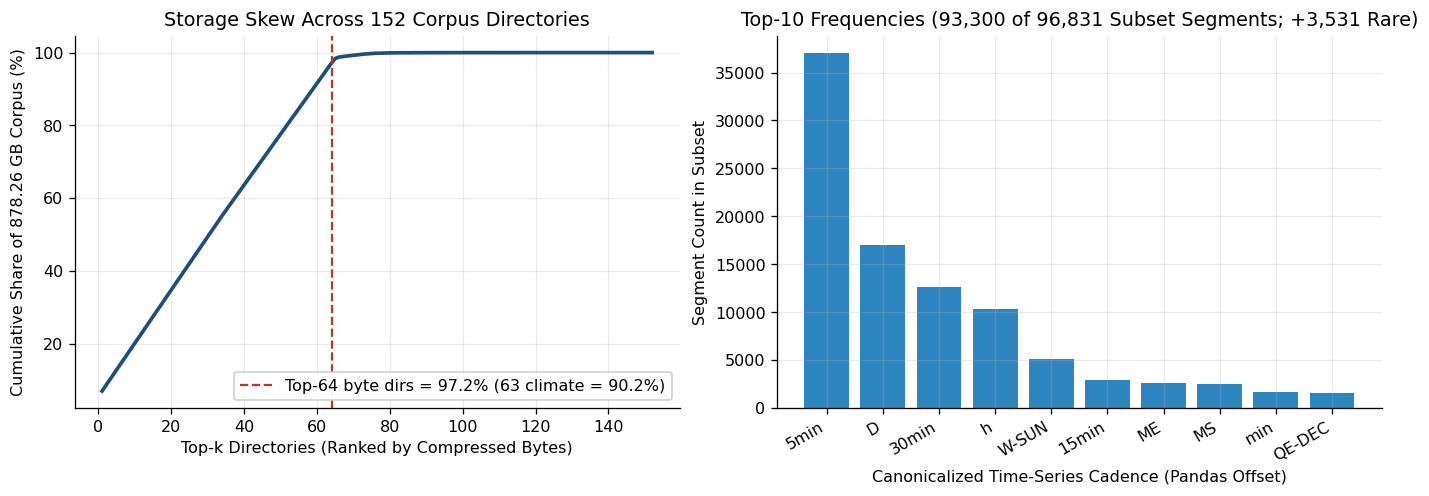

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.2), constrained_layout=True)

sorted_b = np.sort(catalog["full_compressed_bytes"].to_numpy(dtype=np.float64))[::-1]
cum_b = np.cumsum(sorted_b) / sorted_b.sum()
axes[0].plot(np.arange(1, len(cum_b) + 1), cum_b * 100.0, lw=2.3, color="#1f4e79")
axes[0].axvline(64, color="#b03a2e", ls="--", lw=1.4, label="Top-64 byte dirs = 97.2% (63 climate = 90.2%)")
axes[0].set_xlabel("Top-k Directories (Ranked by Compressed Bytes)")
axes[0].set_ylabel("Cumulative Share of 878.26 GB Corpus (%)")
axes[0].set_title("Storage Skew Across 152 Corpus Directories")
axes[0].legend(loc="lower right", framealpha=0.95, facecolor="white")

sub_df = catalog[catalog["in_subset"]].copy()
sub_df["freq_norm"] = sub_df["freq"].astype(str).map(normalize_pandas_freq)
freq_counts = sub_df.groupby("freq_norm")["subset_num_series"].sum().sort_values(ascending=False).head(10)
axes[1].bar(freq_counts.index, freq_counts.values, color="#2e86c1")
top10_n = int(freq_counts.sum())
total_sub_n = int(sub_df["subset_num_series"].sum())
axes[1].set_title(f"Top-10 Frequencies ({top10_n:,} of {total_sub_n:,} Subset Segments; +{total_sub_n - top10_n:,} Rare)")
axes[1].set_xlabel("Canonicalized Time-Series Cadence (Pandas Offset)")
axes[1].set_ylabel("Segment Count in Subset")
axes[1].tick_params(axis="x", rotation=30)
for lbl in axes[1].get_xticklabels():
    lbl.set_ha("right")
plt.show()

## 2. Internal Validation Holdout (`[:-H_freq]` Tail Truncation)

- `SubsetDatasetStore` holds out the final `H_freq` steps (`[-H_freq:]`) of `1,500` pretrain segments across `66` of `87` qualifying datasets (realized `H_freq = 8..48` from the `6..60` cadence schedule, requiring length `>= max(96, 3 * H_freq)`, normalized against `Point Seasonal_Naive` during validation) and permanently strips `[:-H_freq]` from both `train_views` and `Run 5` `TSMixup`.
- Across the full `152`-directory `GiftEvalPretrain` corpus (`results/eda_dataset_catalog.csv`), **zero (`0 / 152`)** directories have `10S` cadence—a key coverage gap explaining zero-shot error spikes on `GIFT-Eval` `10S` cloud telemetry tasks.

In [4]:
_TMP_SUBSET_CTX = None


def _open_subset_store() -> tuple[SubsetDatasetStore, bool]:
    """Open local 93-directory subset if present, else build a tiny deterministic fixture for bare clones."""
    global _TMP_SUBSET_CTX
    real_dir = REPO_ROOT / "data" / "gifteval_pretrain_subset"
    if real_dir.exists() and any(real_dir.glob("*/part-00000.parquet")):
        return SubsetDatasetStore(real_dir, val_num_series=1500), False

    _TMP_SUBSET_CTX = tempfile.TemporaryDirectory(prefix="tsfm_nb01_")
    tmp_root = Path(_TMP_SUBSET_CTX.name)
    rng_fix = np.random.default_rng(7)
    specs = [
        ("demo_large_cov", 40, 2, 160),
        ("demo_medium", 16, 0, 144),
        ("demo_small", 6, 0, 128),
        ("demo_rare", 2, 0, 112),
    ]
    for dname, n_ser, n_cov, t_len in specs:
        ds_dir = tmp_root / dname
        ds_dir.mkdir(parents=True, exist_ok=True)
        t_ax = np.arange(t_len, dtype=np.float32)
        targets = [
            [(np.sin(2.0 * np.pi * t_ax / 24.0 + 0.3 * s_i) + 0.1 * rng_fix.normal(size=t_len)).astype(np.float32).tolist()]
            for s_i in range(n_ser)
        ]
        covs = [
            [np.cos(2.0 * np.pi * t_ax / 12.0 + c_i).astype(np.float32).tolist() for c_i in range(n_cov)] if n_cov > 0 else []
            for _ in range(n_ser)
        ]
        tbl = pa.table(
            {
                "dataset_name": [dname] * n_ser,
                "item_id": [f"s{j}" for j in range(n_ser)],
                "freq": ["H"] * n_ser,
                "target": pa.array(targets, type=pa.list_(pa.list_(pa.float32()))),
                "past_feat_dynamic_real": pa.array(covs, type=pa.list_(pa.list_(pa.float32()))),
            }
        )
        pq.write_table(tbl, ds_dir / "part-00000.parquet")
    return SubsetDatasetStore(tmp_root, val_num_series=2, min_val_len=96), True


manifest_summary = json.loads((REPO_ROOT / "results" / "subset_manifest.json").read_text())
print(
    f"Subset manifest: {manifest_summary['full_corpus_directories']} full dirs -> "
    f"{manifest_summary['subset_directories']} subset dirs "
    f"({manifest_summary['subset_non_climate_directories']} non-climate + "
    f"{len(manifest_summary['subset_climate_directories'])} climate), "
    f"{manifest_summary['subset_total_series']:,} series, {manifest_summary['subset_disk_gb']} GB"
)

store, is_demo_fixture = _open_subset_store()
if is_demo_fixture:
    print("\nNote: local data/gifteval_pretrain_subset/ not mounted; using deterministic temporary Parquet fixture.")
val_examples = store.build_validation_examples(max_examples=25)
val_example0 = val_examples[0]

# Confirm exact boundary alignment and disjointness in train_views vs val_examples.
first_dname, first_row_idx, first_h = store._val_specs[0]
train_pool_first = store._load_train_dir(first_dname)
train_item_first = train_pool_first[first_row_idx]
assert train_item_first.target.shape[1] == val_example0.context_target.shape[1]
assert np.allclose(
    np.nan_to_num(train_item_first.target, nan=0.0),
    np.nan_to_num(val_example0.context_target, nan=0.0),
)
print(
    f"\nVerified holdout boundary for `{first_dname}` row {first_row_idx}: "
    f"train_views T={train_item_first.target.shape[1]}, held-out H_freq={val_example0.horizon} stripped permanently."
)

Subset manifest: 152 full dirs -> 93 subset dirs (89 non-climate + 4 climate), 96,831 series, 2.738 GB



Verified holdout boundary for `largest_2017` row 2485: train_views T=4048, held-out H_freq=48 stripped permanently.


## 3. Dataset Temperature Balancing (`alpha = 1.0 -> 0.35`)

**Question:** Why change `alpha = 1.0` (`Run 0`) to `alpha = 0.35` (`Runs 1..5`) when sampling `93` directories?

Under proportional sampling (`p_d` proportional to `N_d^1.0`), `2,500–5,000`-segment capped directories dominate gradient updates while rare `2–50`-series healthcare/economic datasets receive negligible weight. Conversely, pure uniform sampling (`alpha = 0.0`) risks memorizing tiny datasets in a single pass. Setting `alpha = 0.35` compresses the max/min sampling ratio across the `93` subset directories by `162x` (`2,500.0x` down to `15.5x`) while preserving monotonic volume priority.

Max/Min sampling ratio & normalized entropy across 93 dirs:
  alpha=1.00 : max/min = 2500.0x | H_norm = 0.825
  alpha=0.50 : max/min =   50.0x | H_norm = 0.923
  alpha=0.35 : max/min =   15.5x | H_norm = 0.954
  alpha=0.00 : max/min =    1.0x | H_norm = 1.000


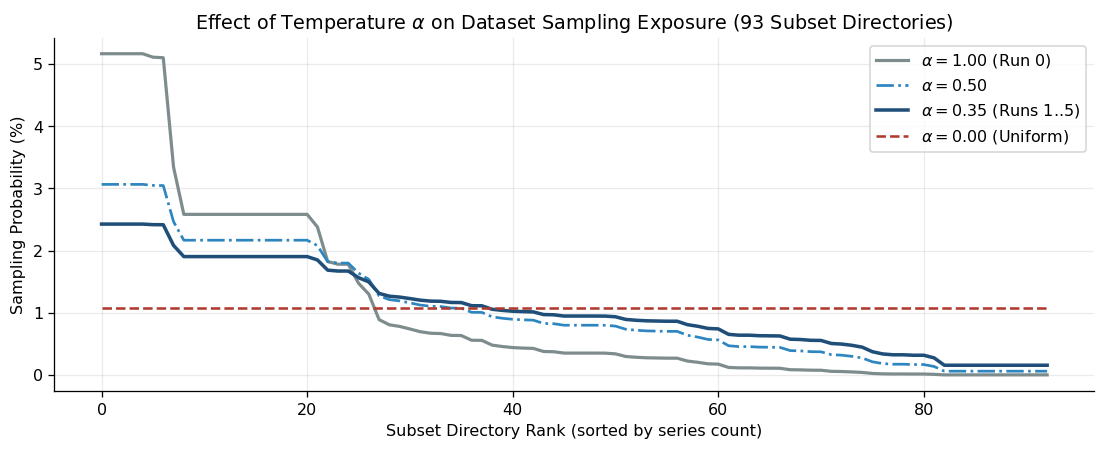

In [5]:
counts = np.array([store.dir_counts[d] for d in store.dir_names], dtype=np.float64)
p10 = store.sampling_probs(1.0)
p05 = store.sampling_probs(0.5)
p035 = store.sampling_probs(0.35)
p00 = store.sampling_probs(0.0)

def _norm_entropy(p: np.ndarray) -> float:
    return float(-(p * np.log(p + 1e-12)).sum() / np.log(len(p)))

print(
    f"Max/Min sampling ratio & normalized entropy across {len(counts)} dirs:\n"
    f"  alpha=1.00 : max/min = {p10.max()/p10.min():6.1f}x | H_norm = {_norm_entropy(p10):.3f}\n"
    f"  alpha=0.50 : max/min = {p05.max()/p05.min():6.1f}x | H_norm = {_norm_entropy(p05):.3f}\n"
    f"  alpha=0.35 : max/min = {p035.max()/p035.min():6.1f}x | H_norm = {_norm_entropy(p035):.3f}\n"
    f"  alpha=0.00 : max/min = {p00.max()/p00.min():6.1f}x | H_norm = {_norm_entropy(p00):.3f}"
)

fig, ax = plt.subplots(figsize=(9.5, 3.8), constrained_layout=True)
order = np.argsort(counts)[::-1]
x = np.arange(len(counts))
ax.plot(x, p10[order] * 100.0, label=r"$\alpha = 1.00$ (Run 0)", lw=2.0, color="#7f8c8d")
ax.plot(x, p05[order] * 100.0, label=r"$\alpha = 0.50$", lw=1.7, ls="-.", color="#2e86c1")
ax.plot(x, p035[order] * 100.0, label=r"$\alpha = 0.35$ (Runs 1..5)", lw=2.2, color="#1f4e79")
ax.plot(x, p00[order] * 100.0, label=r"$\alpha = 0.00$ (Uniform)", lw=1.6, ls="--", color="#b03a2e")
ax.set_xlabel("Subset Directory Rank (sorted by series count)")
ax.set_ylabel("Sampling Probability (%)")
ax.set_title(rf"Effect of Temperature $\alpha$ on Dataset Sampling Exposure ({len(counts)} Subset Directories)")
ax.legend()
plt.show()

## 4. Unit-Equivariant `arcsinh` Scaling, `W = 64` Local Scale & 4-Cycle Blackout Lags

Three subtle invariants in `src/tsfm_proto/scaling.py` prevent numerical failure in zero-shot forecasting:
1. **Exact Scale Equivariance on Micro-SI Series:** `_scale_equivariant_stats_1d` checks relative variation `s > max(1e-6 * |mu|, 1e-12)` instead of adding a fixed `+0.01` floor in variance space. Rescaling a micro-SI series from `[1e-6, 1e-5]` to `[1, 10]` preserves near-machine-precision invariance (`< 2e-15` below in `float64` scalar normalization, and `< 5e-5` across tested decimal SI rescalings inside `float32`-cast `build_group_patch_features`).
2. **Observed-Only Moments (`Runs 2..5`):** Missing values do not pull `mu` toward zero or shrink/distort `sigma`, while all-missing patches stay zeroed so blanked-key masking works cleanly.
3. **`W = 64` Trailing Local Scale + 4-Cycle Observed Lags (`Runs 3..5`):** Even if a contiguous `64`-step pre-origin blackout blanks two full `P=32` patches right before `T_origin`, observed lags step backward across `m in {0, 1, 2, 3}` multiples of `S in {7, 12, 24, 48, 52, 96}` to retrieve real seasonal anchors.

In [6]:
# 1. Scale-equivariance demonstration across 6 orders of magnitude.
rng = np.random.default_rng(7)
base = 2.5e-6 + 4.0e-7 * np.sin(np.linspace(0, 8 * np.pi, 128))
mu_micro, sig_micro = _scale_equivariant_stats_1d(base)
mu_macro, sig_macro = _scale_equivariant_stats_1d(base * 1e6)
norm_micro = np.arcsinh((base - mu_micro) / sig_micro)
norm_macro = np.arcsinh((base * 1e6 - mu_macro) / sig_macro)
print(
    f"Max abs diff between 1e-6 SI series and 1e+0 rescaled series after arcsinh normalization: "
    f"{float(np.max(np.abs(norm_micro - norm_macro))):.2e}"
)

# 2. 64-step pre-origin blackout demonstration on Run 3+ stem features (C_in = 17).
t = np.arange(160, dtype=np.float32)
signal = (100.0 + 0.25 * t + 12.0 * np.sin(2.0 * np.pi * t / 24.0))[None, :]
signal_blk = signal.copy()
signal_blk[:, -64:] = np.nan  # Blank the trailing 64 steps right before origin.

patched, obs_any, mu_obs, sig_obs = build_group_patch_features(
    y_ctx_real=signal_blk,
    left_pad=(-160) % 32,
    n_ctx_patches=5,
    n_hor_patches=2,
    patch_size=32,
    scaling_mode="observed_frozen_origin",
    use_local_scale_and_lags=True,
)
# Channel indices: 7 = lag S=24 value, 13 = lag_ok[S=24].
lag24_val_hor0 = patched[0, 5, :, 7]
lag24_ok_hor0 = patched[0, 5, :, 13]
print(
    f"Horizon patch +1 (under 64-step pre-origin blackout): "
    f"lag_24 resolved on {int(lag24_ok_hor0.sum())}/32 steps via 4-cycle fallback; "
    f"lag_24 range = [{lag24_val_hor0.min():.2f}, {lag24_val_hor0.max():.2f}]"
)

Max abs diff between 1e-6 SI series and 1e+0 rescaled series after arcsinh normalization: 1.50e-15
Horizon patch +1 (under 64-step pre-origin blackout): lag_24 resolved on 32/32 steps via 4-cycle fallback; lag_24 range = [-0.14, 1.44]


## 5. Universal Modulo-32 Origin Alignment & `[1, 32, 128]` Strip Packing

In `src/tsfm_proto/packing.py`, *every* context length `T_ctx >= 1` receives `left_pad = (-T_ctx) % 32` slack steps so that the true forecast origin `T_origin` always sits at **timestep `31` of patch `rel_patch_idx == 0`**. Multiple heterogeneous variable-length windows pack cleanly side-by-side onto a static `[1, 32, 128]` canvas with `~99%` occupancy and zero cross-segment contamination.

Packed batch shape: (1, 32, 128, 32, 17)
Strip occupancy   : 99.54% (4077/4096 patch slots)
Packed segments   : 139 across 123 groups | cov_patches=118 | active loss steps=21,634


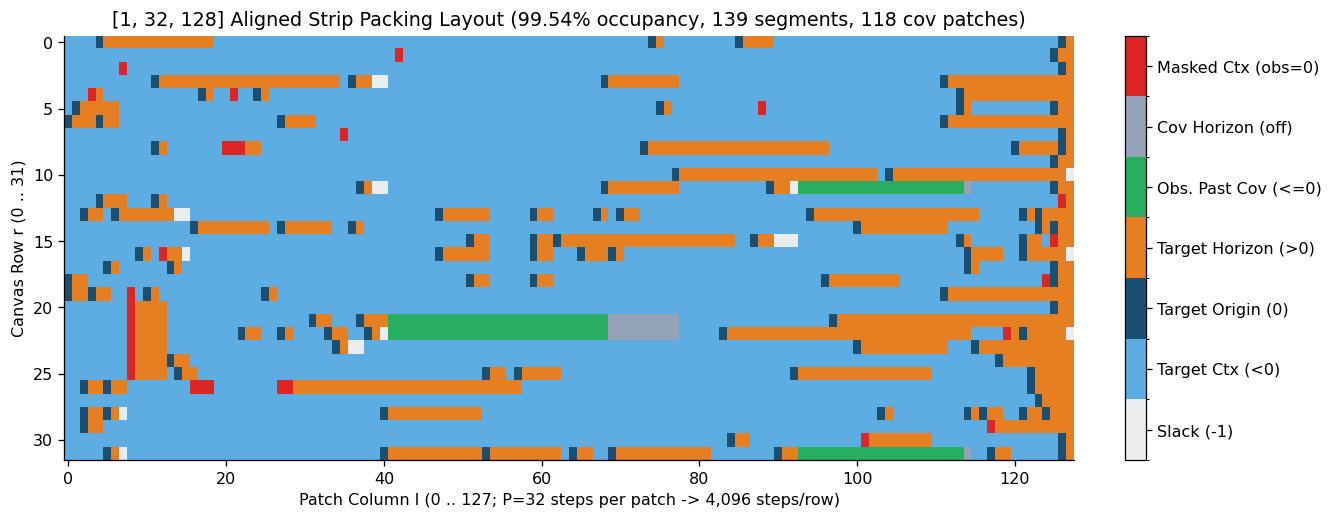

In [7]:
cfg5 = TSFMConfig.from_yaml(REPO_ROOT / "configs" / "run5_coupled_synth_mix.yaml")
probs5 = store.sampling_probs(cfg5.sampling_alpha)
batch_rng = make_step_rng(cfg5.seed, step_idx=1, worker_id=0)
packed = pack_strip_batch(lambda r: store.sample_train_item(r, cfg5, probs5), batch_rng, cfg5)

seg_np = packed.segment_id[0].numpy()  # [32, 128]
rel_np = packed.rel_patch_idx[0].numpy()
cov_np = packed.patch_is_cov[0].numpy()
obs_np = packed.patch_obs_any[0].numpy()
lmask_np = packed.loss_mask[0].numpy()

occupancy = float((seg_np >= 0).mean()) * 100.0
origin_cols = rel_np == 0
n_segments = int(seg_np.max()) + 1
n_groups = int(packed.patch_group_id[0].max().item()) + 1
n_cov_patches = int(((seg_np >= 0) & cov_np).sum())
print(
    f"Packed batch shape: {tuple(packed.patch_inputs.shape)}\n"
    f"Strip occupancy   : {occupancy:.2f}% ({int((seg_np >= 0).sum())}/{seg_np.size} patch slots)\n"
    f"Packed segments   : {n_segments} across {n_groups} groups | cov_patches={n_cov_patches} | active loss steps={int(lmask_np.sum()):,}"
)

fig, ax = plt.subplots(figsize=(11.5, 4.4), constrained_layout=True)
# Discrete 7-class token encoding separating observed past covariates from unobserved future covariate horizon slots.
from matplotlib.colors import BoundaryNorm, ListedColormap

vis = np.zeros(seg_np.shape, dtype=np.int32)
active = seg_np >= 0
vis[active & (~cov_np) & (rel_np < 0) & obs_np] = 1
vis[active & (~cov_np) & origin_cols & obs_np] = 2
vis[active & (~cov_np) & (rel_np > 0)] = 3
vis[active & cov_np & (rel_np <= 0) & obs_np] = 4
vis[active & cov_np & (rel_np > 0)] = 5
vis[active & (rel_np <= 0) & (~obs_np)] = 6
cmap = ListedColormap(["#EAEDED", "#5DADE2", "#1B4F72", "#E67E22", "#27AE60", "#94A3B8", "#DC2626"])
norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5], cmap.N)
im = ax.imshow(vis, aspect="auto", cmap=cmap, norm=norm, interpolation="nearest")
ax.grid(False)
ax.set_xlabel("Patch Column l (0 .. 127; P=32 steps per patch -> 4,096 steps/row)")
ax.set_ylabel("Canvas Row r (0 .. 31)")
ax.set_title(
    f"[1, 32, 128] Aligned Strip Packing Layout ({occupancy:.2f}% occupancy, {n_segments} segments, {n_cov_patches} cov patches)"
)
cbar = fig.colorbar(im, ax=ax, ticks=[0, 1, 2, 3, 4, 5, 6])
cbar.ax.set_yticklabels([
    "Slack (-1)",
    "Target Ctx (<0)",
    "Target Origin (0)",
    "Target Horizon (>0)",
    "Obs. Past Cov (<=0)",
    "Cov Horizon (off)",
    "Masked Ctx (obs=0)",
])
plt.show()

## Summary
- The `2.74 GB` (`93`-directory, `96,831`-segment) stratified subset eliminates `99.7%` of raw storage bloat from gridded climate archives while preserving `100%` of small/medium datasets and all sampling frequencies.
- `SubsetDatasetStore` isolates `1,500` internal validation tails (`[-H_freq:]` across `66` datasets with length `>= max(96, 3 * H_freq)`) and permanently strips `[:-H_freq]` from `train_views` and `Run 5` `TSMixup`.
- Modulo-32 left padding aligns `T_origin` cleanly onto patch `rel_patch_idx == 0`, packing variable-length target and covariate windows to `>99%` density on `[1, 32, 128]`.